# Scanvidence — Radiomics Feature Analysis & Visualization

This notebook performs exploratory data analysis (EDA), quality assurance (QA) audit, and visual diagnostics on the **frozen radiomics feature dataset** extracted from the **BraTS 2023 GLI** cohort (1,063 development cases).

### Pipeline Stages Covered:
1. **Dataset Integrity & Partition Balance** (Train, Validation, Calibration)
2. **Tumor Volumetrics & Sub-Region Anatomy** (WT, TC, ET)
3. **Schema Freeze Audit** (Kept vs. Dropped features)
4. **Collinearity & Correlation Structure** (Motivating Quantum QUBO / LASSO feature selection)
5. **Dimensionality Reduction (PCA)**
6. **Key Morphological & Textural Biomarker Distributions**


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.sans-serif"] = "Helvetica, Arial, DejaVu Sans"

# Paths
DATA_CSV = Path("../cache/radiomics_gt_dev.csv")
SCHEMA_JSON = Path("../cache/radiomics_schema_v1.json")
META_JSON = Path("../cache/radiomics_gt_meta.json")

# Load dataset
df = pd.read_csv(DATA_CSV)
schema = json.loads(SCHEMA_JSON.read_text())
meta = json.loads(META_JSON.read_text())

print(f"Loaded dataset: {df.shape[0]} cases x {df.shape[1]} columns")
print(f"Schema: {schema['n_kept']} kept features out of {schema['n_raw']} raw features")


Loaded dataset: 1063 cases x 269 columns
Schema: 253 kept features out of 264 raw features


## 1. Cohort Partitions & Whole Tumor Volume Distribution
Audit patient-level partition balance across Train, Validation, and Calibration splits.


/var/folders/ty/pqq1ftxd6qd7cf3jpzhz2bmw0000gn/T/ipykernel_72401/2686803125.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="partition", y="wt_volume_cm3", ax=axes[1], palette=colors, flierprops=dict(marker="o", markersize=3))


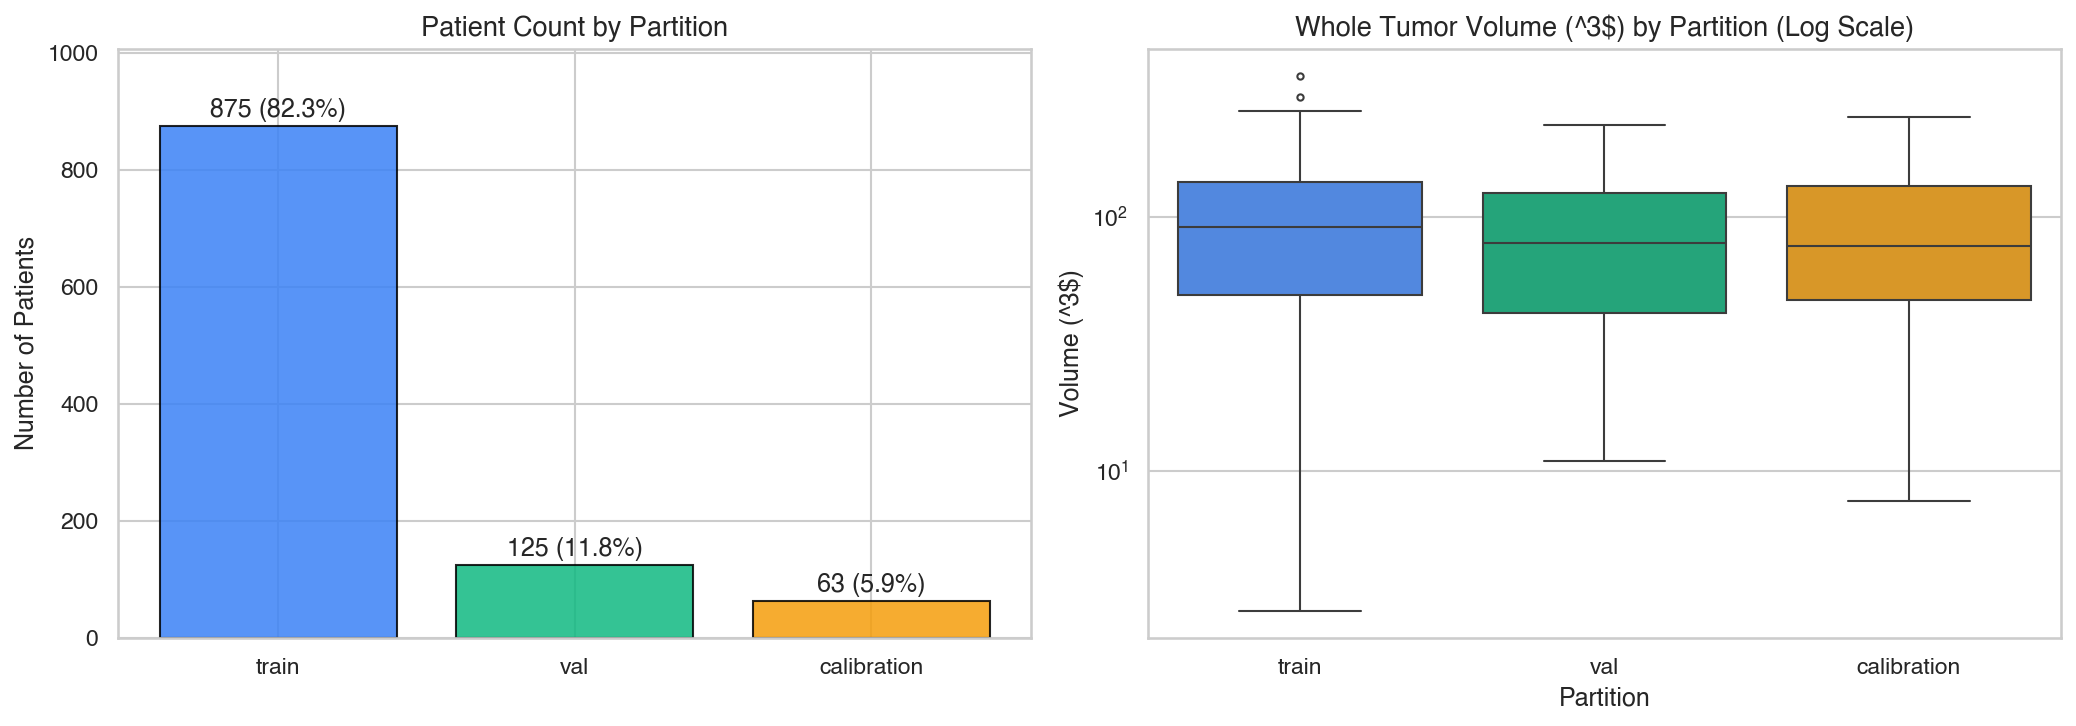

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Partition breakdown
part_counts = df["partition"].value_counts()
colors = ["#3b82f6", "#10b981", "#f59e0b"]
axes[0].bar(part_counts.index, part_counts.values, color=colors, edgecolor="black", alpha=0.85)
for i, (p, c) in enumerate(part_counts.items()):
    axes[0].text(i, c + 15, f"{c} ({c/len(df):.1%})", ha="center", fontweight="bold")
axes[0].set_title("Patient Count by Partition", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of Patients")
axes[0].set_ylim(0, part_counts.max() * 1.15)

# 2. Whole tumor volume distribution (cm3)
sns.boxplot(data=df, x="partition", y="wt_volume_cm3", ax=axes[1], palette=colors, flierprops=dict(marker="o", markersize=3))
axes[1].set_yscale("log")
axes[1].set_title("Whole Tumor Volume (^3$) by Partition (Log Scale)", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Volume (^3$)")
axes[1].set_xlabel("Partition")

plt.tight_layout()
plt.show()


## 2. Anatomical Sub-region Presence & Completeness
In glioblastomas and lower-grade gliomas, the Enhancing Tumor (ET) or necrotic Tumor Core (TC) may be absent or below detection threshold ($< 10$ voxels).


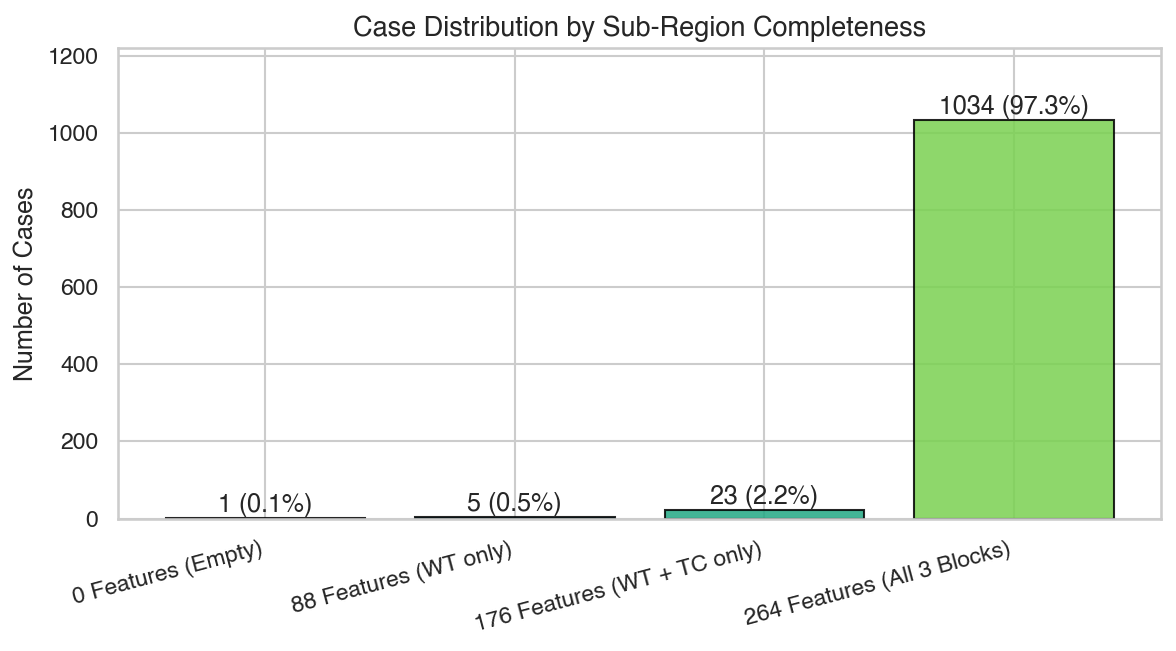

In [3]:
# Compute non-null feature counts per case
feat_cols = [c for c in df.columns if "__original_" in c]
non_null_feats = df[feat_cols].notna().sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
counts = non_null_feats.value_counts().sort_index()

labels = []
for k in counts.index:
    if k >= 250:
        labels.append(f"{k} Features (All 3 Blocks)")
    elif k >= 160:
        labels.append(f"{k} Features (WT + TC only)")
    elif k > 0:
        labels.append(f"{k} Features (WT only)")
    else:
        labels.append(f"{k} Features (Empty)")

bars = ax.bar(labels, counts.values, color=sns.color_palette("viridis", len(counts)), edgecolor="black", alpha=0.85)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 15, f"{val} ({val/len(df):.1%})", ha="center", fontweight="bold")

ax.set_title("Case Distribution by Sub-Region Completeness", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Cases")
ax.set_ylim(0, counts.max() * 1.18)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## 3. Schema Freeze: Feature Class & Block Breakdown
Breakdown of the 253 kept features vs 11 dropped features by feature class (First Order, Shape, GLCM, GLRLM, GLSZM).


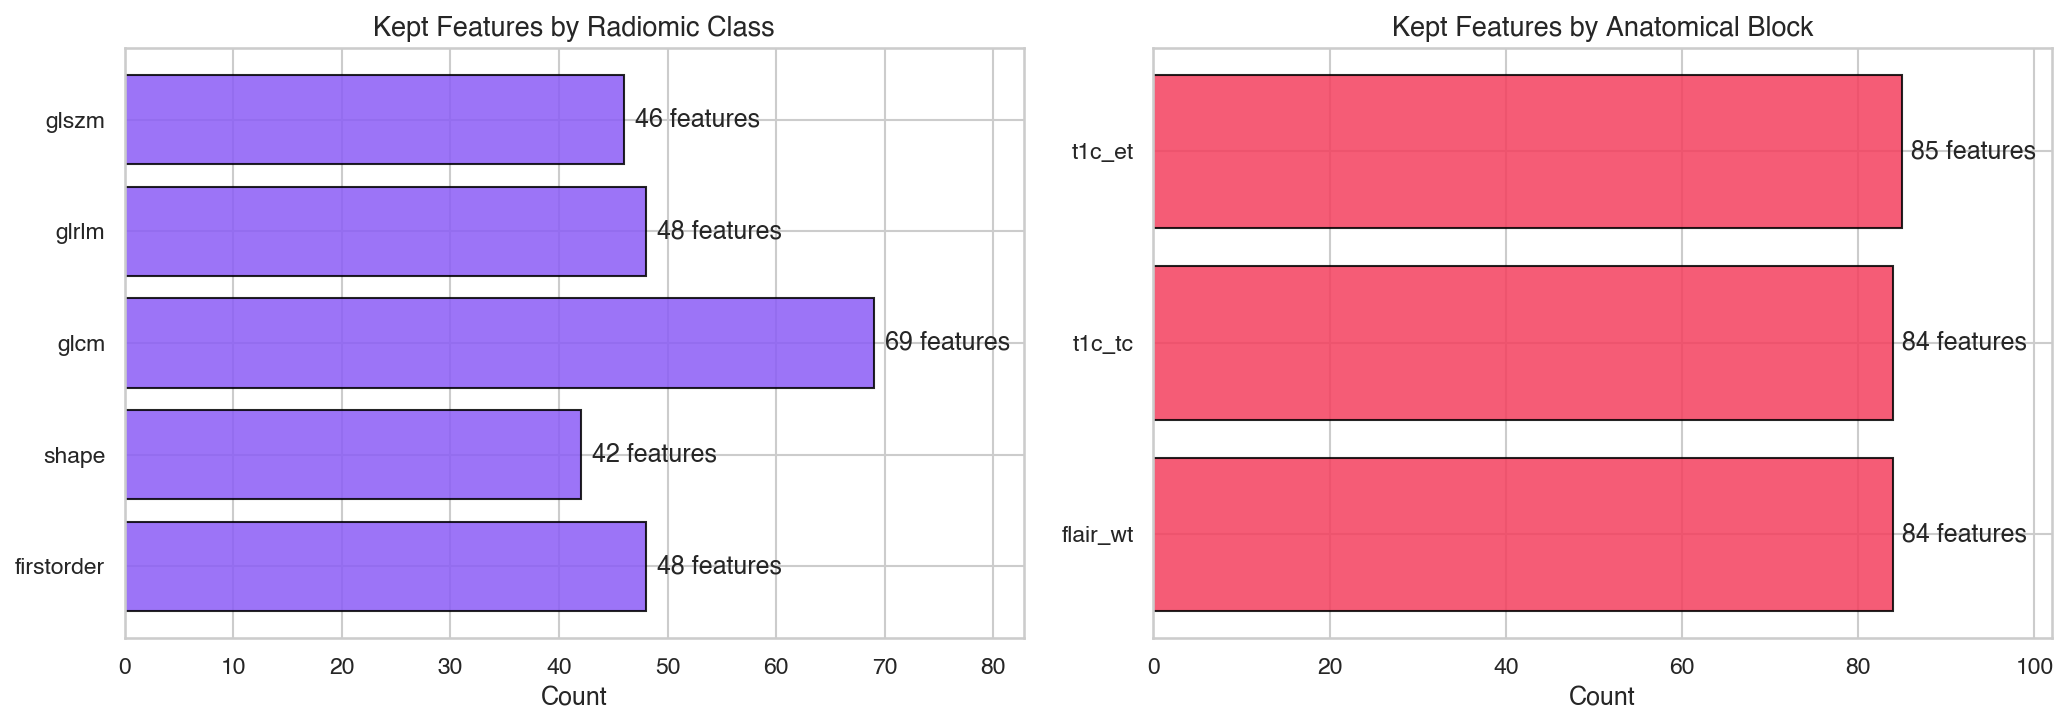

Dropped features summary (QA reasons: near-zero variance or extreme range):
  - flair_wt__original_firstorder_Energy
  - flair_wt__original_firstorder_TotalEnergy
  - flair_wt__original_glcm_ClusterProminence
  - flair_wt__original_glszm_LargeAreaHighGrayLevelEmphasis
  - t1c_tc__original_firstorder_Energy
  - t1c_tc__original_firstorder_TotalEnergy
  - t1c_tc__original_glcm_ClusterProminence
  - t1c_tc__original_glszm_LargeAreaHighGrayLevelEmphasis
  - t1c_et__original_firstorder_Energy
  - t1c_et__original_firstorder_TotalEnergy
  - t1c_et__original_glcm_ClusterProminence


In [4]:
kept_features = schema["feature_ids"]
dropped_features = schema["dropped"]

# Parse feature metadata
classes = ["firstorder", "shape", "glcm", "glrlm", "glszm"]
blocks = ["flair_wt", "t1c_tc", "t1c_et"]

class_counts = {c: sum(1 for f in kept_features if f"_{c}_" in f) for c in classes}
block_counts = {b: sum(1 for f in kept_features if f.startswith(b)) for b in blocks}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
axes[0].barh(list(class_counts.keys()), list(class_counts.values()), color="#8b5cf6", edgecolor="black", alpha=0.85)
for i, (k, v) in enumerate(class_counts.items()):
    axes[0].text(v + 1, i, f"{v} features", va="center", fontweight="bold")
axes[0].set_title("Kept Features by Radiomic Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Count")
axes[0].set_xlim(0, max(class_counts.values()) * 1.2)

# Block distribution
axes[1].barh(list(block_counts.keys()), list(block_counts.values()), color="#f43f5e", edgecolor="black", alpha=0.85)
for i, (k, v) in enumerate(block_counts.items()):
    axes[1].text(v + 1, i, f"{v} features", va="center", fontweight="bold")
axes[1].set_title("Kept Features by Anatomical Block", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Count")
axes[1].set_xlim(0, max(block_counts.values()) * 1.2)

plt.tight_layout()
plt.show()

print("Dropped features summary (QA reasons: near-zero variance or extreme range):")
for df_name in dropped_features:
    print(f"  - {df_name}")


## 4. Feature Collinearity & Redundancy Heatmap
Radiomics matrices naturally exhibit strong collinearity across related texture and morphology measures. This severe redundancy directly motivates **Quantum QUBO and LASSO feature selection (Hypothesis H3)**.


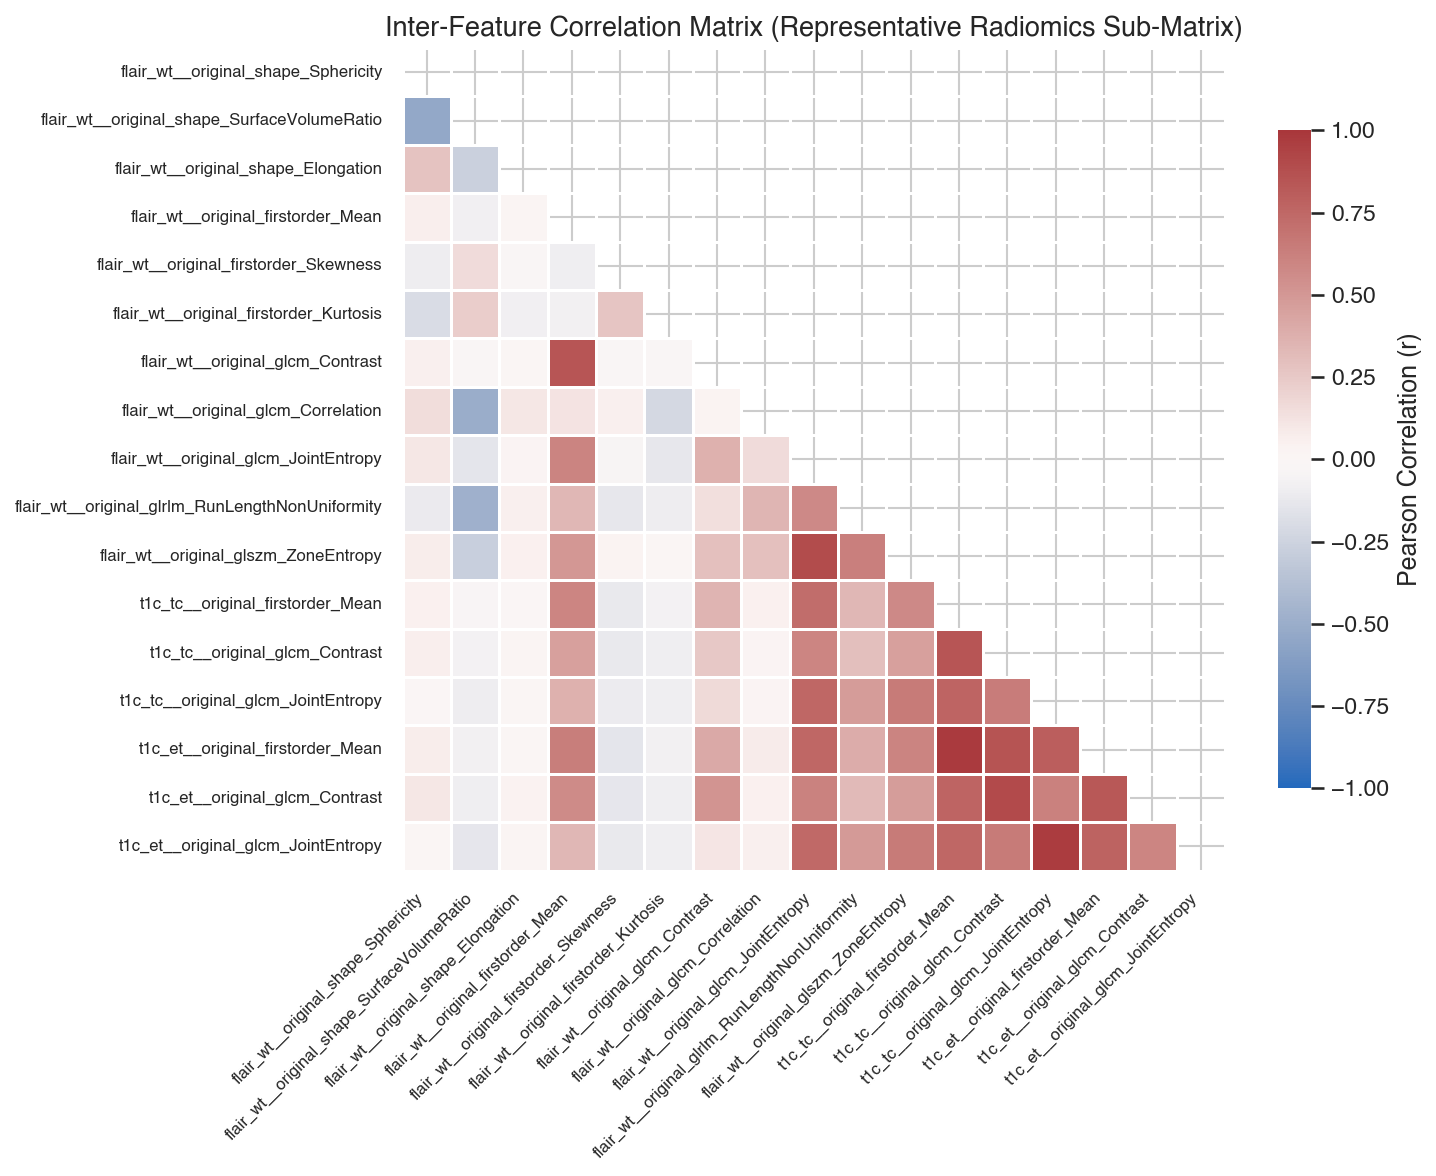

In [5]:
# Select representative set of 18 diverse features
rep_features = [
    "flair_wt__original_shape_Sphericity",
    "flair_wt__original_shape_SurfaceVolumeRatio",
    "flair_wt__original_shape_Elongation",
    "flair_wt__original_firstorder_Mean",
    "flair_wt__original_firstorder_StandardDeviation",
    "flair_wt__original_firstorder_Skewness",
    "flair_wt__original_firstorder_Kurtosis",
    "flair_wt__original_glcm_Contrast",
    "flair_wt__original_glcm_Correlation",
    "flair_wt__original_glcm_JointEntropy",
    "flair_wt__original_glrlm_RunLengthNonUniformity",
    "flair_wt__original_glszm_ZoneEntropy",
    "t1c_tc__original_firstorder_Mean",
    "t1c_tc__original_glcm_Contrast",
    "t1c_tc__original_glcm_JointEntropy",
    "t1c_et__original_firstorder_Mean",
    "t1c_et__original_glcm_Contrast",
    "t1c_et__original_glcm_JointEntropy",
]
valid_rep = [f for f in rep_features if f in df.columns]

corr = df[valid_rep].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, center=0, square=True,
            linewidths=.5, cbar_kws=dict(shrink=.8, label="Pearson Correlation (r)"))
plt.title("Inter-Feature Correlation Matrix (Representative Radiomics Sub-Matrix)", fontsize=13, fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


## 5. Dimensionality Reduction: PCA Projection of the 253D Radiomics Space
Evaluating the global manifold variance captured by principal components across the patient cohort using Singular Value Decomposition.


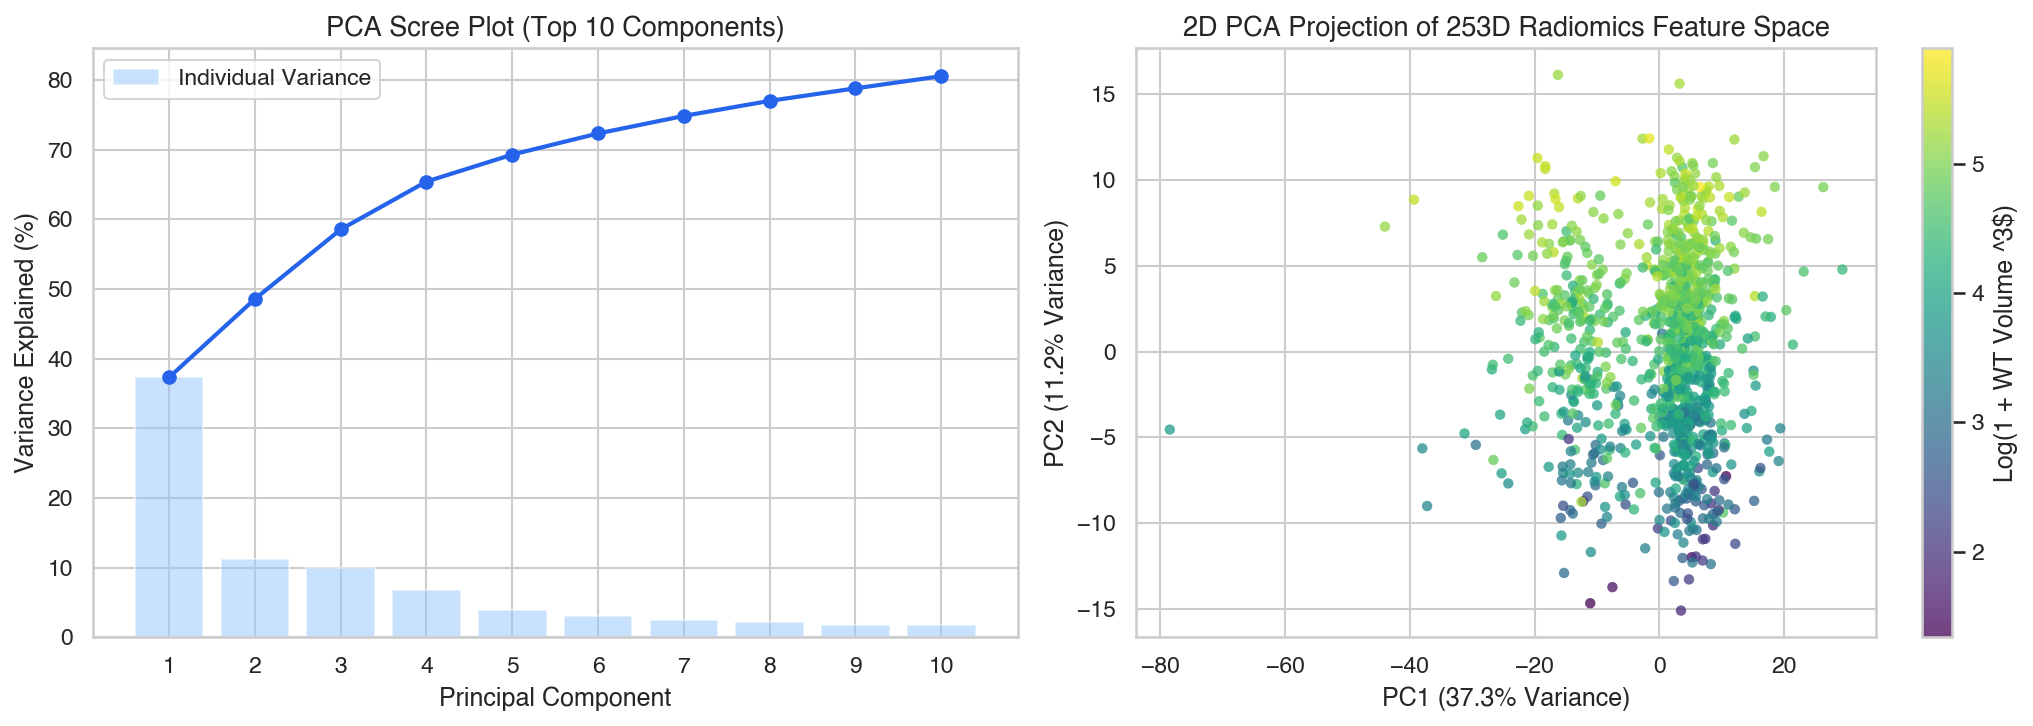

In [6]:
# Prepare matrix (impute median for PCA visualization)
X_raw = df[kept_features].copy()
X_imputed = X_raw.fillna(X_raw.median())
X_std = (X_imputed - X_imputed.mean()) / (X_imputed.std() + 1e-12)

# SVD PCA
U, S, Vt = np.linalg.svd(X_std.values, full_matrices=False)
X_pca = U * S
exp_var_ratio = (S**2) / np.sum(S**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scree Plot (Cumulative Explained Variance)
cum_var = np.cumsum(exp_var_ratio[:10]) * 100
axes[0].plot(range(1, 11), cum_var, marker="o", color="#2563eb", linewidth=2)
axes[0].bar(range(1, 11), exp_var_ratio[:10] * 100, alpha=0.5, color="#93c5fd", label="Individual Variance")
axes[0].set_title("PCA Scree Plot (Top 10 Components)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Variance Explained (%)")
axes[0].set_xticks(range(1, 11))
axes[0].legend()

# 2. 2D Scatter Plot colored by Whole Tumor Volume
scatter = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=np.log1p(df["wt_volume_cm3"]), cmap="viridis", alpha=0.75, s=25, edgecolor="none")
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label("Log(1 + WT Volume ^3$)")
axes[1].set_title("2D PCA Projection of 253D Radiomics Feature Space", fontsize=13, fontweight="bold")
axes[1].set_xlabel(f"PC1 ({exp_var_ratio[0]*100:.1f}% Variance)")
axes[1].set_ylabel(f"PC2 ({exp_var_ratio[1]*100:.1f}% Variance)")

plt.tight_layout()
plt.show()


## 6. Key Phenotypic Biomarkers across Tumor Compartments
Comparing morphology (Sphericity) and microstructural texture heterogeneity (GLCM Joint Entropy & Contrast) across Whole Tumor (WT), Tumor Core (TC), and Enhancing Tumor (ET).


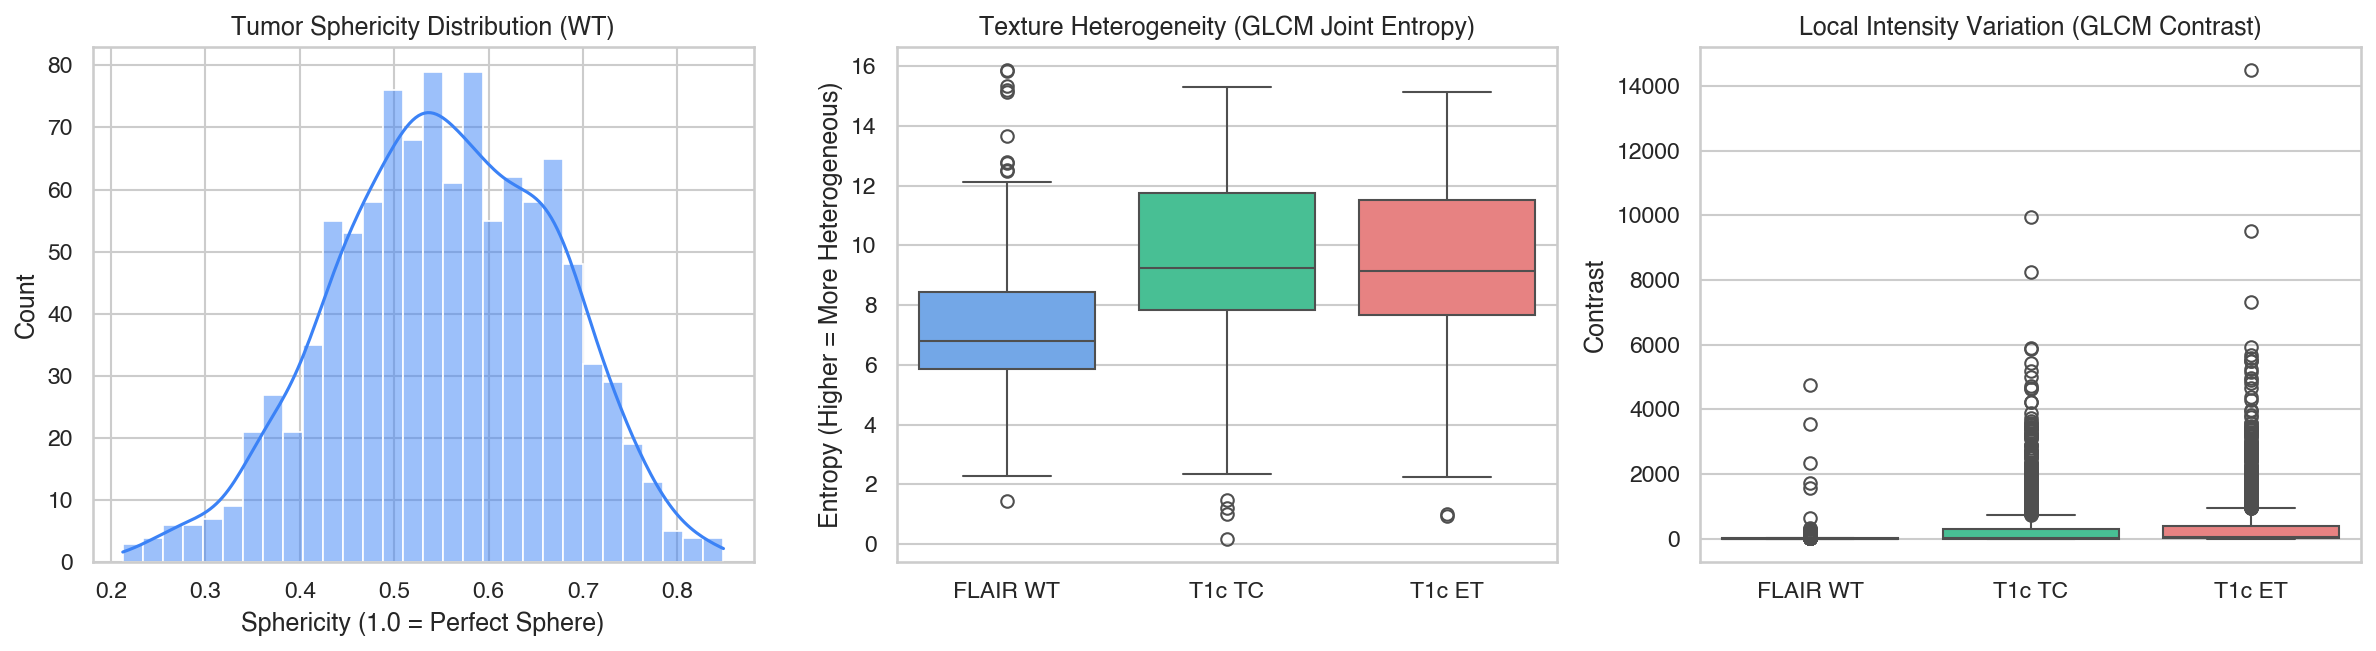

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Sphericity Distribution
if "flair_wt__original_shape_Sphericity" in df.columns:
    sns.histplot(df["flair_wt__original_shape_Sphericity"].dropna(), kde=True, ax=axes[0], color="#3b82f6", bins=30)
    axes[0].set_title("Tumor Sphericity Distribution (WT)", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Sphericity (1.0 = Perfect Sphere)")

# 2. GLCM Joint Entropy Comparison across Blocks
entropy_cols = [c for c in ["flair_wt__original_glcm_JointEntropy", "t1c_tc__original_glcm_JointEntropy", "t1c_et__original_glcm_JointEntropy"] if c in df.columns]
entropy_data = df[entropy_cols].rename(columns={
    "flair_wt__original_glcm_JointEntropy": "FLAIR WT",
    "t1c_tc__original_glcm_JointEntropy": "T1c TC",
    "t1c_et__original_glcm_JointEntropy": "T1c ET"
})
sns.boxplot(data=entropy_data, ax=axes[1], palette=["#60a5fa", "#34d399", "#f87171"])
axes[1].set_title("Texture Heterogeneity (GLCM Joint Entropy)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Entropy (Higher = More Heterogeneous)")

# 3. GLCM Contrast Comparison across Blocks
contrast_cols = [c for c in ["flair_wt__original_glcm_Contrast", "t1c_tc__original_glcm_Contrast", "t1c_et__original_glcm_Contrast"] if c in df.columns]
contrast_data = df[contrast_cols].rename(columns={
    "flair_wt__original_glcm_Contrast": "FLAIR WT",
    "t1c_tc__original_glcm_Contrast": "T1c TC",
    "t1c_et__original_glcm_Contrast": "T1c ET"
})
sns.boxplot(data=contrast_data, ax=axes[2], palette=["#60a5fa", "#34d399", "#f87171"])
axes[2].set_title("Local Intensity Variation (GLCM Contrast)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Contrast")

plt.tight_layout()
plt.show()


## 7. Molecular Biomarker: MGMT Promoter Methylation Distribution
Auditing the clinical MGMT promoter methylation ground-truth labels (0 = Unmethylated, 1 = Methylated) across development partitions.


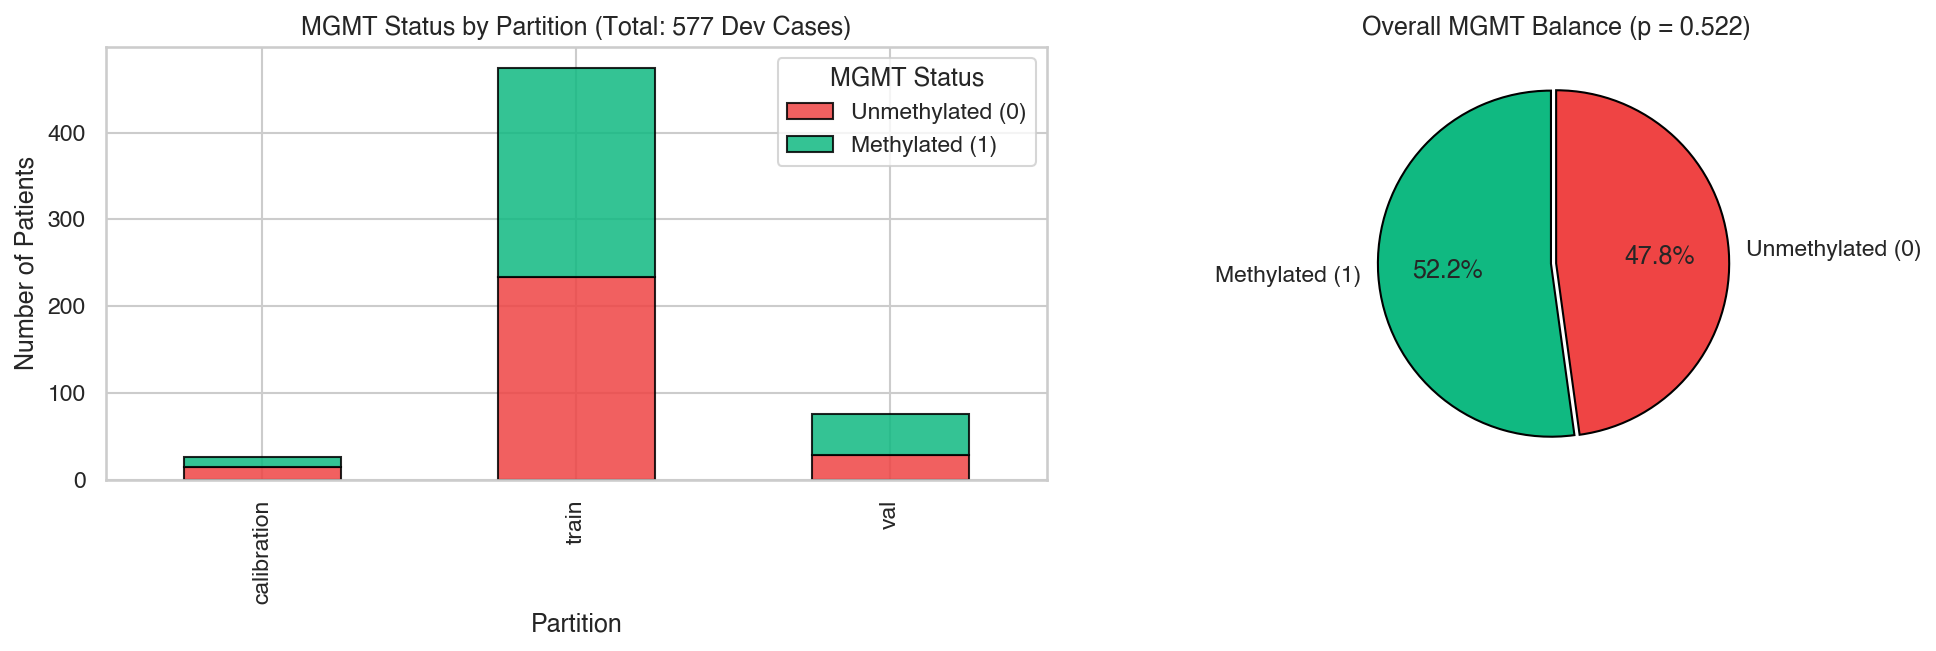

In [8]:
mgmt_path = Path('../data/manifests/mgmt_labels_v1.csv')
if mgmt_path.exists():
    mgmt = pd.read_csv(mgmt_path)
    df_mgmt = df.dropna(subset=['mgmt'])
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    
    # 1. Partition Breakdown of MGMT Cohort
    part_mgmt = pd.crosstab(df_mgmt['partition'], df_mgmt['mgmt'])
    part_mgmt.plot(kind='bar', stacked=True, ax=axes[0], color=['#ef4444', '#10b981'], edgecolor='black', alpha=0.85)
    axes[0].set_title('MGMT Status by Partition (Total: 577 Dev Cases)', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Number of Patients')
    axes[0].set_xlabel('Partition')
    axes[0].legend(['Unmethylated (0)', 'Methylated (1)'], title='MGMT Status')
    
    # 2. Overall Balance
    overall_counts = df_mgmt['mgmt'].value_counts()
    axes[1].pie(overall_counts, labels=['Methylated (1)', 'Unmethylated (0)'], autopct='%1.1f%%',
                colors=['#10b981', '#ef4444'], startangle=90, explode=(0.03, 0),
                wedgeprops={'edgecolor': 'black', 'linewidth': 1})
    axes[1].set_title(f'Overall MGMT Balance (p = {df_mgmt["mgmt"].mean():.3f})', fontsize=12, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
